Imports

In [ ]:
import sys
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from data_prep import load_raw_data, rescale_features, get_X_y, LABEL_COL, TOP5_FEATURES_FULL, CBC_ONLY_FEATURES
from pqc import build_full_pqc
from training import train, evaluate_full, transpile_circuit, predict_probs
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, balanced_accuracy_score

load full data

In [5]:
df1 = load_raw_data()
df1 = rescale_features(df1, TOP5_FEATURES_FULL)
X1, y1 = get_X_y(df1, TOP5_FEATURES_FULL, LABEL_COL)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42, stratify=y1)

qc1, _, omega1 = build_full_pqc(num_features=5)
qc1 = transpile_circuit(qc1)
num_weights1 = len(omega1)

untrained control test cell

In [6]:
from sklearn.metrics import roc_auc_score

rng = np.random.RandomState(0)
i1 = np.where(y1_test == 1)[0]
i0 = rng.choice(np.where(y1_test == 0)[0], size=len(i1), replace=False)
idx = np.concatenate([i1, i0])

aucs = []
for s in range(8):
    w0 = 2*np.pi*np.random.RandomState(s).random_sample(num_weights1)
    probs = predict_probs(qc1, X1_test[idx], w0, shots=100)
    aucs.append(roc_auc_score(y1_test[idx], probs))

print("Untrained AUCs:", np.round(aucs, 3))
print("Mean:", np.mean(aucs), "Std:", np.std(aucs))

Untrained AUCs: [0.485 0.405 0.501 0.511 0.488 0.488 0.518 0.431]
Mean: 0.4782986724101405 Std: 0.037209839521489325


Multi-seed experiment runner

In [ ]:
def run_multiseed_experiment(X_train_full, y_train_full, X_test, y_test, num_features,
                               seeds, epochs, lr, shots, batch_mode='balanced',
                               class_weight=None, checkpoint_prefix='run'):
    all_metrics = []
    for seed in seeds:
        print(f"\n=== seed={seed} ===")
        qc, _, omega = build_full_pqc(num_features)
        qc = transpile_circuit(qc)
        num_weights = len(omega)

        w, ch, eh = train(
            qc, X_train_full, y_train_full, num_weights,
            epochs=epochs, lr=lr, shots=shots, batch_mode=batch_mode,
            class_weight=class_weight, seed=seed,
            checkpoint_path=f'{checkpoint_prefix}_seed{seed}.pkl', resume=True
        )

        X_val, y_val = X_train_full[-100:], y_train_full[-100:]
        val_probs = predict_probs(qc, X_val, w, shots=shots)
        best_thresh, best_bal_acc = 0.5, 0
        for t in np.arange(0.05, 0.96, 0.05):
            pred = (val_probs >= t).astype(int)
            ba = balanced_accuracy_score(y_val, pred)
            if ba > best_bal_acc:
                best_bal_acc, best_thresh = ba, t

        test_probs = predict_probs(qc, X_test, w, shots=shots)
        test_pred_default = (test_probs >= 0.5).astype(int)
        test_pred_tuned = (test_probs >= best_thresh).astype(int)

        metrics = {
            'seed': seed,
            'best_threshold': best_thresh,
            'roc_auc': roc_auc_score(y_test, test_probs),
            'accuracy_default': float(np.mean(test_pred_default == y_test)),
            'accuracy_tuned': float(np.mean(test_pred_tuned == y_test)),
            'balanced_accuracy_tuned': balanced_accuracy_score(y_test, test_pred_tuned),
            'precision_tuned': precision_score(y_test, test_pred_tuned, zero_division=0),
            'recall_tuned': recall_score(y_test, test_pred_tuned, zero_division=0),
            'f1_tuned': f1_score(y_test, test_pred_tuned, zero_division=0),
        }
        print(metrics)
        all_metrics.append(metrics)
    return all_metrics

def summarize(all_metrics, name):
    print(f"\n=== {name} summary across {len(all_metrics)} seeds ===")
    for key in ['roc_auc', 'accuracy_tuned', 'balanced_accuracy_tuned', 'f1_tuned']:
        vals = [m[key] for m in all_metrics]
        print(f"  {key}: {np.mean(vals):.3f} ± {np.std(vals):.3f}  (range {min(vals):.3f}-{max(vals):.3f})")

Load CBC-only data

In [ ]:
df2 = load_raw_data()
df2 = rescale_features(df2, CBC_ONLY_FEATURES)
X2, y2 = get_X_y(df2, CBC_ONLY_FEATURES, LABEL_COL)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)

RUN THIS FIRST ON THE GPU MACHINE

In [ ]:
import time
start = time.time()
_ = predict_probs(qc1, X1_test[:1], np.random.random(num_weights1)*2*np.pi, shots=300)
print(f"Single call: {time.time()-start:.3f}s")

Full-feature experiment

In [ ]:
SEEDS = [1, 2]
EPOCHS = 10
LR = 0.2
SHOTS = 300

fullfeature_metrics = run_multiseed_experiment(
    X1_train, y1_train, X1_test, y1_test, 5,
    seeds=SEEDS, epochs=EPOCHS, lr=LR, shots=SHOTS,
    batch_mode='balanced', checkpoint_prefix='ff'
)
summarize(fullfeature_metrics, "Full-feature")

CBC-only experiment

In [ ]:
cbconly_metrics = run_multiseed_experiment(
    X2_train, y2_train, X2_test, y2_test, 5,
    seeds=SEEDS, epochs=EPOCHS, lr=LR, shots=SHOTS,
    batch_mode='balanced', checkpoint_prefix='cbc'
)
summarize(cbconly_metrics, "CBC-only")

Build the circuit

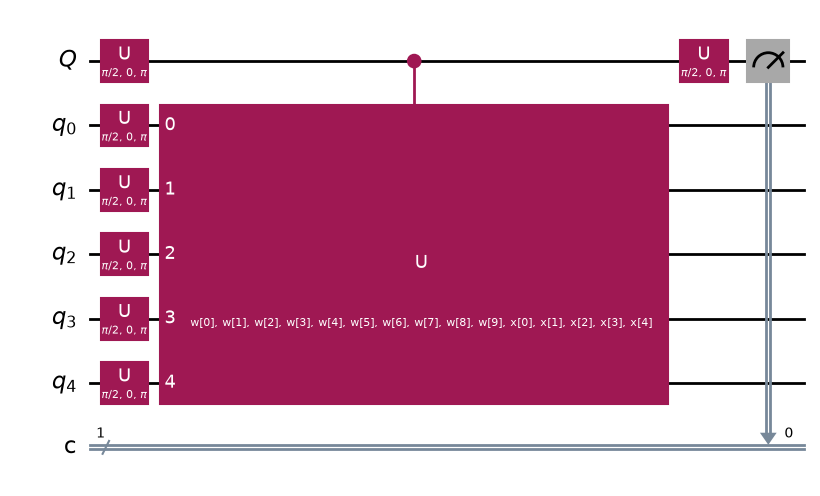

In [ ]:
qc, x_params, omega_params = build_full_pqc(num_features=5)
num_weights = len(omega_params)
qc.decompose().draw("mpl")